# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Edwards, Kamal Sangameswaran, Jiaxian Wang


**Date:** 11/4/2026

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   8  18  85 156 228 137  93  10   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  13 183 254 254 254 254 254 254 210 147   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  16 179 254 254 254 254 254 254 254 254 251  97   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0 160 254 254 253 172  65  65 101 243 254 254 233  25   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0 148 140  47  46   0   0   0   0  84 247 254 25

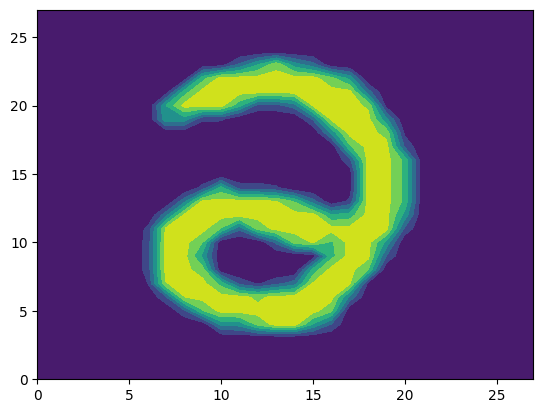

5 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  24  96 255 253 173  12   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  16 186 251 253 251 235  27   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  16 189 251 251 253 235  63   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  72 251 251 251 229  66   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  60 228 251 251 251  59   0   0   

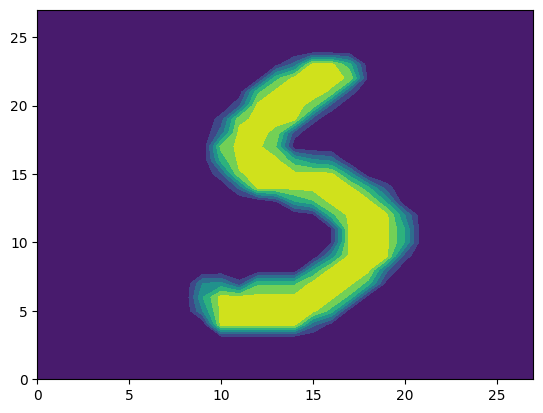

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  62 208 254 254 255 254 241 156  47   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 164 253 253 253 254 253 253 253 247  20   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  11 238 221 127 127 217 197 222 253 25

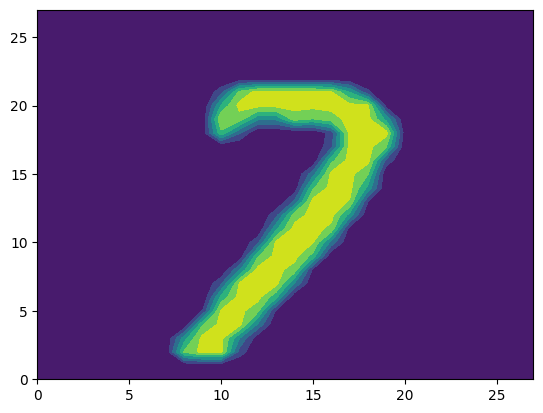

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  50   7   0   0   0   0   0   0   0   0   0  12 198 133   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  69 253  80   0   0   0   0   0   0   0   0   0  18 254 246   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 208 191   1   0   0   0   0   0   0   0   0   0  1

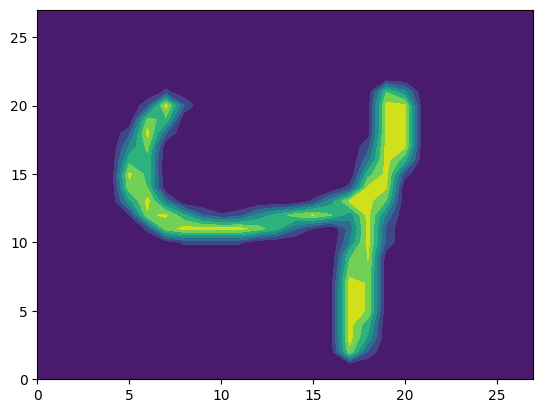

5 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   5   9  32 144 176 176   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   3  31 116 223 254 255 254 254 254   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  25 101 115 184 198 254 25

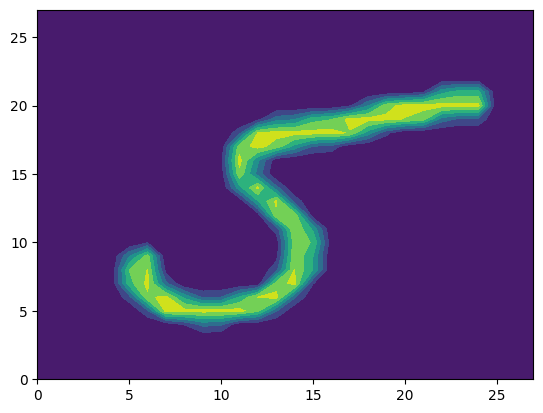

In [8]:
# Q1: Load and Visualize the Data
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the course data from the data folder or the current directory
try:
    with open('data/minst.pkl', 'rb') as f:
        data = pickle.load(f)
except FileNotFoundError:
    with open('minst.pkl', 'rb') as f:
        data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Display the labels, pixel values, and images for the first five test digits
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()


In [9]:
# Q2: Shapes of the Data
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"X_train[i] shape: {X_train.shape[1:]}")
print(f"X_test[i] shape: {X_test.shape[1:]}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

# each image is a 28 x 28 matrix of pixel values. The first dimension of
# X_train and X_test counts the images, and each label vector has one
# digit label for each image. All images in each array have the same shape.


X_train shape: (5000, 28, 28)
X_test shape: (1000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (5000,)
y_test shape: (1000,)


In [10]:
# Q3: Reshaping Images into Feature Vectors
X_train_flat = np.array([img.reshape(784) for img in X_train])
X_test_flat = np.array([img.reshape(784) for img in X_test])

print(f"Reshaped Training Matrix: {X_train_flat.shape}")
print(f"Reshaped Testing Matrix: {X_test_flat.shape}")

# each 28 x 28 image becomes a vector of 784 pixel values.
# Each row represents one image, and each column represents one pixel.


Reshaped Training Matrix: (5000, 784)
Reshaped Testing Matrix: (1000, 784)


In [11]:
# Q4: Selecting the Number of Neighbors
# Use a validation split from the training data to compare k values
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_flat, y_train, test_size=0.2, random_state=42, stratify=y_train
)

best_k = 1
best_val_acc = 0
k_values = [1, 3, 5, 7, 9]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr, y_tr)
    val_preds = knn.predict(X_val)
    val_acc = accuracy_score(y_val, val_preds)
    print(f"k = {k} -> Validation Accuracy = {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_k = k

print(f"Best k among the values tested: {best_k}")

# k = 1 has the highest validation accuracy among the values tested
# on this split. The test set is reserved for the final evaluation.


k = 1 -> Validation Accuracy = 0.9290
k = 3 -> Validation Accuracy = 0.9250
k = 5 -> Validation Accuracy = 0.9190
k = 7 -> Validation Accuracy = 0.9240
k = 9 -> Validation Accuracy = 0.9250
Best k among the values tested: 1


In [12]:
# Q5: Test Accuracy and Confusion Matrix
opt_knn = KNeighborsClassifier(n_neighbors=best_k)
opt_knn.fit(X_train_flat, y_train)
y_pred = opt_knn.predict(X_test_flat)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy with k={best_k}: {test_accuracy*100:.2f}%")
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
print("\nConfusion Matrix (rows = actual digits, columns = predicted digits):")
print(cm)

report = classification_report(y_test, y_pred, output_dict=True)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

f1_scores = {str(i): report[str(i)]['f1-score'] for i in range(10)}
best_digit = max(f1_scores, key=f1_scores.get)
worst_digit = min(f1_scores, key=f1_scores.get)
print(f"Best performing digit: {best_digit} (F1 = {f1_scores[best_digit]:.4f})")
print(f"Worst performing digit: {worst_digit} (F1 = {f1_scores[worst_digit]:.4f})")

# the classifier correctly predicts 93.30% of the test images.
# Most entries are on the diagonal of the confusion matrix, which means
# the predicted digit usually matches the actual digit. The best F1-score
# is for 7, while 8 has the lowest F1-score. Distinct strokes can make
# digits easier to identify, while variations in handwriting can make
# different digits look similar to a pixel-distance classifier like kNN.


Test Accuracy with k=1: 93.30%

Confusion Matrix (rows = actual digits, columns = predicted digits):
[[ 98   0   1   0   0   0   0   0   0   0]
 [  0 113   0   0   0   0   0   0   0   0]
 [  1   6  88   2   0   0   1   1   1   0]
 [  0   1   2  95   0   1   0   0   3   0]
 [  0   0   0   0  91   0   1   0   0   6]
 [  0   0   0   8   0  79   0   0   1   2]
 [  1   0   0   0   0   1  96   0   0   0]
 [  0   0   0   0   0   0   0 104   0   0]
 [  1   4   0   7   1   4   0   1  79   0]
 [  0   0   2   1   3   1   0   2   0  90]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        99
           1       0.91      1.00      0.95       113
           2       0.95      0.88      0.91       100
           3       0.84      0.93      0.88       102
           4       0.96      0.93      0.94        98
           5       0.92      0.88      0.90        90
           6       0.98      0.98      0.98        98
           

In [13]:
# Q6: Most Common Classification Mistakes
mistakes = []
for true_label in range(10):
    for pred_label in range(10):
        if true_label != pred_label:
            count = cm[true_label, pred_label]
            if count > 0:
                mistakes.append((count, true_label, pred_label))

mistakes.sort(reverse=True, key=lambda x: x[0])
print("Top 5 most frequent errors in the confusion matrix:")
for idx, (count, true, pred) in enumerate(mistakes[:5]):
    print(f"{idx+1}. Digit {true} was misclassified as {pred} exactly {count} times.")

# the most common errors are 5 predicted as 3 (8 times), 8 as 3 (7 times),
# and 2 as 1 and 4 as 9 (6 times each). These digits can share similar
# strokes, so differences in handwriting may make them harder to separate.
# This is a possible explanation of the pattern, rather than proof of
# why each individual image was misclassified.


Top 5 most frequent errors in the confusion matrix:
1. Digit 5 was misclassified as 3 exactly 8 times.
2. Digit 8 was misclassified as 3 exactly 7 times.
3. Digit 2 was misclassified as 1 exactly 6 times.
4. Digit 4 was misclassified as 9 exactly 6 times.
5. Digit 8 was misclassified as 1 exactly 4 times.


In [14]:
# Q7: Representing Color Photos as Tabular Data
# a color photo can be represented as a 3D array with shape (H, W, 3).
# H is the height, W is the width, and the three channels are red, green,
# and blue. For an 8-bit RGB image, each channel has values from 0 to 255.

# flattening this array gives a vector with H * W * 3 values. For N images
# of the same size, these vectors form a table with shape (N, H * W * 3).
# Each row represents one photo, and each column represents one color
# channel at one pixel location, such as Pixel_0_Red, Pixel_0_Green,
# Pixel_0_Blue, and Pixel_1_Red. The table can then be used as input to
# a standard machine learning classifier.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** `87b4c91b451562f5f6ed44cf53663098cae5cc4e`
- **AI tool and model used:** Chat GPT 6 Astra

### *Prompts used

1. Be my Phase 2 agent, look through my current code and answers, make your own version and improve them wherever possible, then make a numbered list summarizing your changes.

### *AI-proposed changes


1. Show the first ten test digits in a labeled grayscale grid and make the first five pixel matrices expandable.
2. Check each split’s image and label shapes, then flatten the entire array in one step and verify that every pixel can be restored.
3. Compare the same five candidate k values with five-fold stratified cross-validation on the training set. Report the mean and spread of the validation scores.
4. Plot a labeled test confusion matrix and check its diagonal against the number of correct predictions. Use per-digit F1 and recall to explain the results.
5. Include every error tied at fifth place, report each count as a share of the actual digit, and show test images from the most frequent mistake.
6. Demonstrate RGB flattening with two small photos, named pixel-channel columns, and a check that the original photos can be reconstructed.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
| --- | --- | --- |
| 1 | Accept | The grid shows ten labels together, and each of the first five matrices can be inspected. |
| 2 | Accept | All 5,000 training images and 1,000 test images passed the 784-pixel round-trip check. |
| 3 | Accept | Every k used the same five folds. k = 1 had the highest mean accuracy (93.66%). |
| 4 | Accept | The diagonal totals 933 correct predictions out of 1,000, matching the 93.30% test accuracy. |
| 5 | Accept | Both four-count ties appear. The most common mistake, 5 → 3, accounts for 8 of 90 fives. |
| 6 | Accept | The two six-feature rows reconstruct both original RGB photos exactly. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

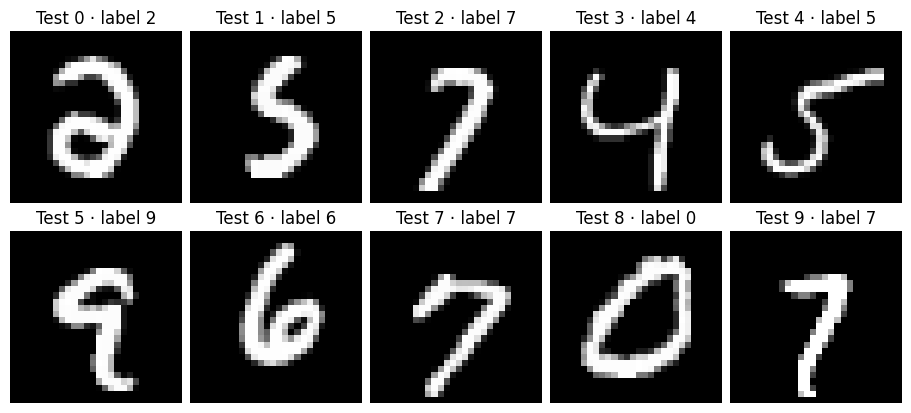

X_train: (5000, 28, 28) | X_train[i]: (28, 28) | y_train: (5000,)
X_test: (1000, 28, 28) | X_test[i]: (28, 28) | y_test: (1000,)
X_train_flat: (5000, 784)
X_test_flat: (1000, 784)


In [15]:
# Q1. Load the course data and inspect the handwritten digits
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

paths = [Path("data/minst.pkl"), Path("minst.pkl")]
data_path = next((path for path in paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Upload the course file minst.pkl to data/ or the notebook directory.")
with data_path.open("rb") as file:
    digits_data = pickle.load(file)

X_train, y_train = digits_data["X_train"], digits_data["y_train"]
X_test, y_test = digits_data["X_test"], digits_data["y_test"]

fig, axes = plt.subplots(2, 5, figsize=(9, 4), constrained_layout=True)
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"Test {i} · label {y_test[i]}")
    ax.axis("off")
plt.show()

# Expand a row to compare a digit above with its exact pixel values.
for i in range(5):
    pixels = np.array2string(X_test[i], threshold=X_test[i].size, max_line_width=140)
    display(HTML(f"<details><summary>Test {i} · label {y_test[i]} · pixel matrix</summary>"
                 f"<pre>{pixels}</pre></details>"))

# Q2. The first axis counts images. Each 28 × 28 image has one digit label.
for split, images, labels in [("train", X_train, y_train), ("test", X_test, y_test)]:
    print(f"X_{split}: {images.shape} | X_{split}[i]: {images.shape[1:]} | y_{split}: {labels.shape}")
    assert images.shape[1:] == (28, 28) and labels.shape == (len(images),)

# Q3. Each row is an image. Column 28*r + c contains the pixel at row r, column c.
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)
for split, images, flat in [("train", X_train, X_train_flat), ("test", X_test, X_test_flat)]:
    assert flat.shape == (len(images), 784)
    assert np.array_equal(flat.reshape(images.shape), images)
    print(f"X_{split}_flat: {flat.shape}")

k,Mean validation accuracy,SD across folds
1,93.66%,0.74%
3,93.42%,1.04%
5,93.28%,1.02%
7,93.34%,0.94%
9,92.86%,0.85%


Best k among [1, 3, 5, 7, 9]: 1 (mean validation accuracy 93.66%).
Test accuracy: 933/1000 = 93.30%; 67 errors.


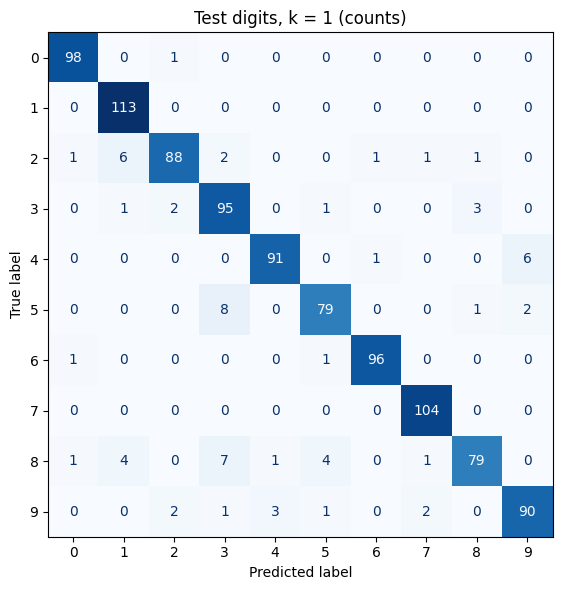

,precision,recall,f1-score,support
0,0.970,0.990,0.980,99
1,0.911,1.000,0.954,113
2,0.946,0.880,0.912,100
3,0.841,0.931,0.884,102
4,0.958,0.929,0.943,98
5,0.919,0.878,0.898,90
6,0.980,0.980,0.980,98
7,0.963,1.000,0.981,104
8,0.940,0.814,0.873,97
9,0.918,0.909,0.914,99


Highest F1: digit(s) 7 (0.981).
Lowest F1: digit(s) 8 (0.873).


In [16]:
# Q4. Choose k using the training images only
# Every k is scored on the same five stratified folds. The ascending grid
# gives the smaller k priority if the mean validation accuracies tie.
candidate_k = [1, 3, 5, 7, 9]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": candidate_k},
                      scoring="accuracy", cv=folds, refit=True)
search.fit(X_train_flat, y_train)

cv_results = pd.DataFrame({
    "k": candidate_k,
    "Mean validation accuracy": search.cv_results_["mean_test_score"],
    "SD across folds": search.cv_results_["std_test_score"],
})
display(cv_results.style.hide(axis="index").format({
    "Mean validation accuracy": "{:.2%}", "SD across folds": "{:.2%}"
}))
best_k = search.best_params_["n_neighbors"]
print(f"Best k among {candidate_k}: {best_k} (mean validation accuracy {search.best_score_:.2%}).")

# Q5. GridSearchCV refits the winning model on all training images.
# Predict the held-out test labels once and use those predictions for Q5 and Q6.
y_pred = search.predict(X_test_flat)
digits = np.arange(10)
cm = confusion_matrix(y_test, y_pred, labels=digits)
correct = int(np.trace(cm))
accuracy = accuracy_score(y_test, y_pred)
assert cm.sum() == len(y_test) and correct == np.count_nonzero(y_pred == y_test)
print(f"Test accuracy: {correct}/{len(y_test)} = {accuracy:.2%}; {len(y_test) - correct} errors.")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=digits).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test digits, k = {best_k} (counts)")
plt.tight_layout()
plt.show()

# Each diagonal cell counts correct predictions of that digit.
report = classification_report(y_test, y_pred, labels=digits, output_dict=True, zero_division=0)
per_digit = pd.DataFrame(report).T.loc[[str(digit) for digit in digits]]
display(per_digit.style.format({"precision": "{:.3f}", "recall": "{:.3f}",
                                "f1-score": "{:.3f}", "support": "{:.0f}"}))
f1 = per_digit["f1-score"]
print(f"Highest F1: digit(s) {', '.join(f1.index[f1 == f1.max()])} ({f1.max():.3f}).")
print(f"Lowest F1: digit(s) {', '.join(f1.index[f1 == f1.min()])} ({f1.min():.3f}).")

Actual,Predicted,Count,Share of actual digit
5,3,8,8.9%
8,3,7,7.2%
2,1,6,6.0%
4,9,6,6.1%
8,1,4,4.1%
8,5,4,4.1%


Actual 5 → predicted 3: 8 cases. Reverse direction: 1 case(s).


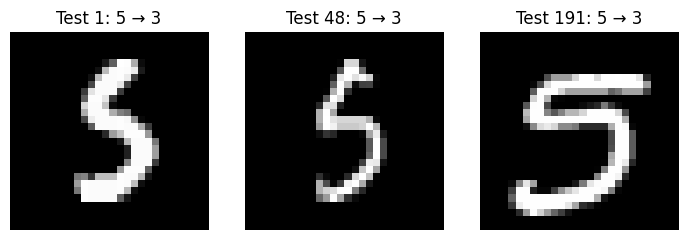

,p00_R,p00_G,p00_B,p01_R,p01_G,p01_B
Photo A,255,0,0,0,0,255
Photo B,0,255,0,255,255,255


In [17]:
# Q6. Rank actual → predicted mistakes. Include every pair tied at fifth place.
true_digit, pred_digit = np.where((cm > 0) & ~np.eye(len(digits), dtype=bool))
mistakes = pd.DataFrame({
    "Actual": digits[true_digit],
    "Predicted": digits[pred_digit],
    "Count": cm[true_digit, pred_digit],
    "Share of actual digit": cm[true_digit, pred_digit] / cm.sum(axis=1)[true_digit],
})
assert mistakes["Count"].sum() == len(y_test) - correct
top_errors = mistakes.nlargest(5, "Count", keep="all")
display(top_errors.style.hide(axis="index").format({"Share of actual digit": "{:.1%}"}))

# Look at real examples of the most frequent mix-up and count the reverse mistake.
if not top_errors.empty:
    actual, predicted = top_errors.iloc[0][["Actual", "Predicted"]].astype(int)
    examples = np.flatnonzero((y_test == actual) & (y_pred == predicted))[:3]
    print(f"Actual {actual} → predicted {predicted}: {cm[actual, predicted]} cases. "
          f"Reverse direction: {cm[predicted, actual]} case(s).")
    fig, axes = plt.subplots(1, len(examples), figsize=(2.4 * len(examples), 2.4), squeeze=False)
    for ax, i in zip(axes.flat, examples):
        ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"Test {i}: {y_test[i]} → {y_pred[i]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Q7. An 8-bit RGB image has shape (height, width, 3) and values from 0 to 255.
# For N same-size photos, flatten each image in row, column, channel order:
# the table has shape (N, height * width * 3), with one photo per row.
# Example: two 1 × 2 photos. Photo A has a red pixel followed by a blue pixel.
photos = np.array([[[[255, 0, 0], [0, 0, 255]]],
                   [[[0, 255, 0], [255, 255, 255]]]], dtype=np.uint8)
rgb_table = pd.DataFrame(photos.reshape(len(photos), -1), index=["Photo A", "Photo B"],
                         columns=["p00_R", "p00_G", "p00_B", "p01_R", "p01_G", "p01_B"])
assert np.array_equal(rgb_table.to_numpy().reshape(photos.shape), photos)
display(rgb_table)

**Q1–Q3. Images and features**

The first five test images are labeled 2, 5, 7, 4, and 5. Each image is a 28 × 28 grid of grayscale values. The training and test image arrays have shapes `(5000, 28, 28)` and `(1000, 28, 28)`. Their label vectors have shapes `(5000,)` and `(1000,)`. Flattening gives 5,000 training rows and 1,000 test rows with 784 features each. The same column refers to the same pixel position in every image.

**Q4. Choosing k**

Among 1, 3, 5, 7, and 9 neighbors, **k = 1** had the highest mean validation accuracy across the five training folds (93.66%). Its lead over k = 3 (93.42%) was 0.24 percentage points. That small gap supports choosing k = 1 for this run, while leaving open which value would win on another sample.

**Q5. Test performance**

The final model correctly classified **933 of 1,000 test digits (93.30%)**. The table gives counts for each actual digit (row) and prediction (column). The diagonal shows that all 104 sevens were recognized. Sevens had the highest F1 score (0.981), which balances precision and recall. Eights had the lowest (0.873). The model recognized only 79 of 97 actual eights, even though 79 of its 84 predictions of eight were correct.

| Actual ↓ / Predicted → | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| **0** | 98 | 0 | 1 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| **1** | 0 | 113 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| **2** | 1 | 6 | 88 | 2 | 0 | 0 | 1 | 1 | 1 | 0 |
| **3** | 0 | 1 | 2 | 95 | 0 | 1 | 0 | 0 | 3 | 0 |
| **4** | 0 | 0 | 0 | 0 | 91 | 0 | 1 | 0 | 0 | 6 |
| **5** | 0 | 0 | 0 | 8 | 0 | 79 | 0 | 0 | 1 | 2 |
| **6** | 1 | 0 | 0 | 0 | 0 | 1 | 96 | 0 | 0 | 0 |
| **7** | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 104 | 0 | 0 |
| **8** | 1 | 4 | 0 | 7 | 1 | 4 | 0 | 1 | 79 | 0 |
| **9** | 0 | 0 | 2 | 1 | 3 | 1 | 0 | 2 | 0 | 90 |

**Q6. Which mistakes stand out?**

The most common mistake was **5 → 3** (8 of 90 fives, 8.9%). The reverse happened only once. Next came **8 → 3** (7), then **2 → 1** and **4 → 9** (6 each). Two pairs tied for fifth with 4 errors each, **8 → 1** and **8 → 5**. The model often erred in the same direction. In total, 15 of its 18 false predictions of three came from fives and eights. A gap in a loop or a shifted stroke could make a digit closer to a three in pixel space. The matrix measures that pattern. The example images let us inspect individual cases.

**Q7. A color photo as one row**

Use three 8-bit values per pixel, in red, green, blue order. A one-row photo with a red pixel followed by a blue pixel becomes `[255, 0, 0, 0, 0, 255]`. Stacking one such row per photo gives a table of shape `(N, H × W × 3)` for equally sized photos. Keeping the pixel order, channel order, height, and width makes the conversion reversible.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI agent did a pretty good job overall. It improved the original solution by making the code more organized, adding better visualizations, and including more detailed explanations of the results. One of the biggest changes was replacing the original validation split with five-fold cross-validation to compare different values of k, which made the model selection process more reliable. It also added a labeled confusion matrix, calculated more detailed classification metrics, and showed actual examples of digits that the model misclassified. Another useful improvement was checking that the images could be flattened and reshaped back to their original dimensions without losing information. I verified the final results and saw that the model achieved a test accuracy of 93.30%, correctly classifying 933 out of 1,000 images. The best value was k = 1, which had a cross-validation accuracy of 93.66%. My main concern is that the AI's list of changes might not include every single modification it made, meaning I'm still relying partly on its own summary when reviewing the work. There is also the possibility that I missed smaller issues during my review. However, considering the verification I did and the fact that the results were consistent, I think the changes were reasonable and improved the original solution overall.